Pesos finales W_I: [ 0.4399 -0.5573  0.1966  0.3297 -0.2881]
Bias/offset final: -0.143
MSE normalizado inicial: 0.0483
MSE normalizado final: 0.0015
MSE en la escala original: 0.5095
Rango de y_generado: (np.float64(-6.6856), np.float64(11.8425))
Rango de y_estimado: (np.float64(-5.3905), np.float64(10.1681))


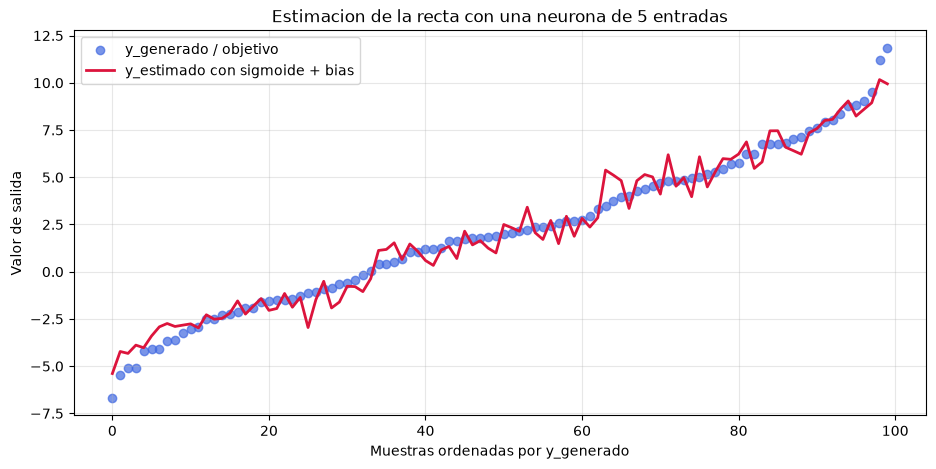

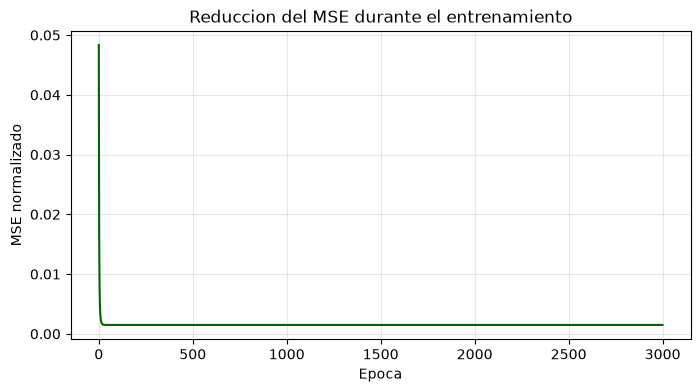

In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generar 100 ejemplos con 5 entradas por ejemplo.
numero_muestras = 100
numero_entradas = 5
X = np.random.uniform(-2, 2, size=(numero_muestras, numero_entradas))

# Funcion objetivo: salida continua de la recta/hiperplano que se quiere estimar.
pesos_reales = np.array([1.8, -2.2, 0.7, 1.3, -1.1])
sesgo_real = 2.0
ruido = np.random.normal(0, 0.6, numero_muestras)
y_generado = X @ pesos_reales + sesgo_real + ruido

# La sigmoide produce valores entre 0 y 1.
def activacion_sigmoide(z):
    z_limitado = np.clip(z, -                         500, 500)
    return 1 / (1 + np.exp(-z_limitado))
    q|1|    |||||||||||||||||||||                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       
# Funcion de costo MSE: compara los valores reales con los estimados.
def funcion_costo(y_real, y_estimado):
    return np.mean((y_real - y_estimado) ** 2)

# La sigmoide necesita un objetivo entre 0 y 1 durante el entrenamiento.
y_min = y_generado.min()
y_max = y_generado.max()
y_objetivo = (y_generado - y_min) / (y_max - y_min)

# Parametros iniciales: 5 pesos y un offset/bias.
W_I = np.zeros(numero_entradas)
bias = 0.0
tasa_aprendizaje = 1.5
epocas = 3000
historial_costo = []

# Entrenamiento iterativo con descenso de gradiente.
for epoca in range(epocas):
    suma_ponderada = X @ W_I + bias
    y_estimado_normalizado = activacion_sigmoide(suma_ponderada)

    error_normalizado = y_estimado_normalizado - y_objetivo
    costo = funcion_costo(y_objetivo, y_estimado_normalizado)
    historial_costo.append(costo)

    derivada_sigmoide = y_estimado_normalizado * (1 - y_estimado_normalizado)
    gradiente_W = (2 / numero_muestras) * (X.T @ (error_normalizado * derivada_sigmoide))
    gradiente_bias = (2 / numero_muestras) * np.sum(error_normalizado * derivada_sigmoide)

    W_I -= tasa_aprendizaje * gradiente_W
    bias -= tasa_aprendizaje * gradiente_bias

# Desnormalizar la prediccion para recuperar la escala de la recta original.
y_estimado_normalizado_final = activacion_sigmoide(X @ W_I + bias)
y_estimado_final = y_min + y_estimado_normalizado_final * (y_max - y_min)
error_cuadratico_medio = funcion_costo(y_generado, y_estimado_final)

print("Pesos finales W_I:", np.round(W_I, 4))
print("Bias/offset final:", round(bias, 4))
print("MSE normalizado inicial:", round(historial_costo[0], 4))
print("MSE normalizado final:", round(historial_costo[-1], 4))
print("MSE en la escala original:", round(error_cuadratico_medio, 4))
print("Rango de y_generado:", (round(y_min, 4), round(y_max, 4)))
print("Rango de y_estimado:", (round(y_estimado_final.min(), 4), round(y_estimado_final.max(), 4)))

# Repetir la estimacion de la recta: objetivo y prediccion en la escala original.
orden = np.argsort(y_generado)
plt.figure(figsize=(11, 5))
plt.scatter(
    np.arange(numero_muestras),
    y_generado[orden],
    color="royalblue",
    alpha=0.7,
    label="y_generado / objetivo",
)
plt.plot(
    y_estimado_final[orden],
    color="crimson",
    linewidth=2,
    label="y_estimado con sigmoide + bias",
)
plt.title("Estimacion de la recta con una neurona de 5 entradas")
plt.xlabel("Muestras ordenadas por y_generado")
plt.ylabel("Valor de salida")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Evolucion del MSE usado para entrenar la neurona.
plt.figure(figsize=(8, 4))
plt.plot(historial_costo, color="darkgreen")
plt.title("Reduccion del MSE durante el entrenamiento")
plt.xlabel("Epoca")
plt.ylabel("MSE normalizado")
plt.grid(alpha=0.3)
plt.show()

# Regresion con una neurona artificial

## Neurona de clasificacion on/off

Una neurona **on/off** es una neurona artificial que utiliza una funcion de activacion por umbral. Si la suma ponderada de sus entradas supera el umbral, devuelve `1` (**on**); de lo contrario, devuelve `0` (**off**).

Se utiliza principalmente para problemas de **clasificacion binaria**, por ejemplo:

- correo spam o no spam,
- paciente enfermo o sano,
- compra aprobada o rechazada,
- imagen perteneciente o no a una categoria.

No es adecuada para regresion porque solo puede producir dos valores. Por ejemplo, no puede estimar correctamente un precio de `250.5` o una temperatura de `23.7`.

## Objetivo de la actividad

En esta actividad se transforma una neurona de clasificacion on/off en una neurona capaz de resolver un problema de **regresion**. La neurona recibe cinco entradas, combina cada entrada con un peso, agrega un sesgo y produce una salida continua.

El objetivo es ajustar los pesos `W_I` y el `bias` para que `y_estimado` se acerque a `y_generado`.

## MSE: error cuadratico medio

El **MSE** (*Mean Squared Error* o error cuadratico medio) es una funcion de costo que mide que tan lejos estan las predicciones de los valores reales. Eleva cada error al cuadrado, por lo que los errores grandes tienen mayor influencia.

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_{real,i} - y_{estimado,i})^2
$$

En este ejercicio se usa para evaluar la diferencia entre `y_generado` y `y_estimado`. Un MSE menor indica una mejor aproximacion.

## Bias, offset o sesgo

El `bias` es un valor adicional que se suma a la combinacion ponderada de las entradas. Permite desplazar la prediccion hacia arriba o hacia abajo aunque todas las entradas valgan cero.

**Analogia:** es como ajustar el punto de partida de una balanza antes de pesar objetos.

## Funcion de activacion

La activacion define como se transforma la suma ponderada en la salida final.

- **On/off:** devuelve `0` o `1`; se usa para clasificacion binaria.
- **Lineal:** devuelve valores continuos; es apropiada para regresion.
- **Sigmoide:** devuelve valores entre `0` y `1`; se usa frecuentemente para probabilidades binarias.

En esta actividad se utiliza la sigmoide con una normalizacion temporal de la salida. Al final, la prediccion se desnormaliza para recuperar la escala original de la recta.

## Aplicaciones y no usos

La regresion con una neurona puede utilizarse como modelo introductorio para estimar precios, temperaturas, consumo de energia o demanda.

Una sola neurona no es adecuada cuando la relacion entre entradas y salida es muy no lineal, cuando se necesitan muchas categorias o cuando se trabajan directamente con imagenes, audio o texto sin extraer caracteristicas.

## Interpretacion del resultado

El notebook imprime los pesos finales, el `bias`, el MSE inicial y el MSE final. Si el MSE disminuye, la neurona aprendio una relacion aproximada entre las cinco entradas y la salida objetivo. Debido al ruido agregado, el MSE no tiene que llegar exactamente a cero.
